# Exploratory Data Analysis — PLN (Profil Beban Listrik PLN)
Dataset PLN berisi data load profile pelanggan listrik PT PLN. Setiap file merepresentasikan satu pelanggan dengan data deret waktu konsumsi daya dalam interval 30 menit (atau 1 jam). Label anomali bersifat **per file** (bukan per timestep), sehingga satu file dinyatakan normal (0) atau anomali (1) secara keseluruhan.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from pathlib import Path
import ast, warnings, os
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'lines.linewidth': 0.9,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

BASE = Path(r'C:\CARLA-20260708-1450')
COLORS = {'normal': '#2196F3', 'anomaly': '#FF5722', 'val': '#4CAF50'}

# Buat folder output jika belum ada
FIG_DIR = BASE / 'results' / 'figures2'
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f'Setup selesai. Output gambar: {FIG_DIR}')


Setup selesai. Output gambar: C:\CARLA-20260708-1450\results\figures2


## 1. Memuat Daftar File dan Label

In [5]:
DATA_DIR = BASE / 'datasets' / 'PLN' / 'processed'

file_labels = pd.read_csv(DATA_DIR / 'file_labels.csv')
print(f"Total file : {len(file_labels)}")
print(f"\nDistribusi label:")
print(file_labels['label'].value_counts().rename({0: 'Normal (0)', 1: 'Anomali (1)'}).to_string())
print()
display(file_labels.head(10))


Total file : 44

Distribusi label:
label
Normal (0)     34
Anomali (1)    10



,fname,label
0,120030005909-a.npy,1
1,120030745857-a.npy,1
2,120120158879-a.npy,1
3,121101064783-a.npy,1
4,121160469026-a.npy,1
5,121170436934-a.npy,1
6,121170485044-a.npy,1
7,122130645743-a.npy,1
8,125100007230-a.npy,1
9,126150138887-a.npy,1


## 2. Distribusi Label (Class Imbalance)

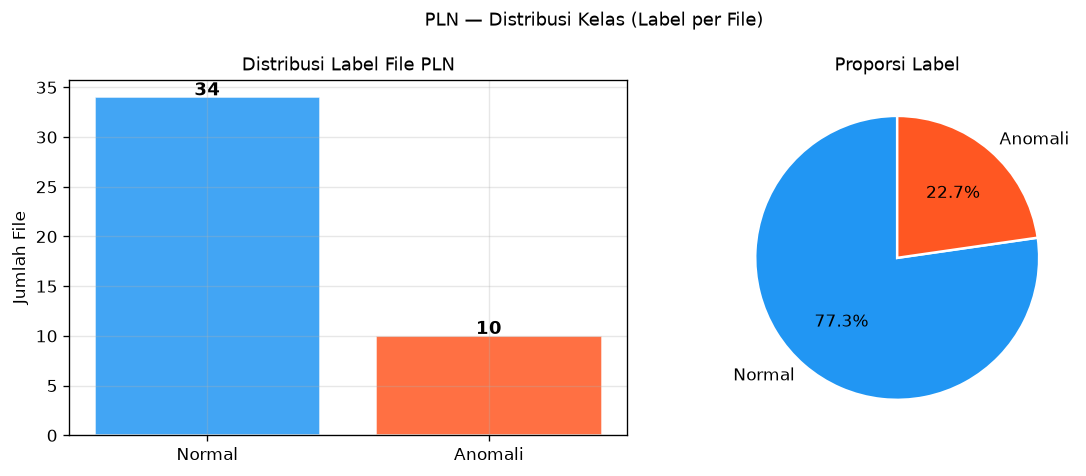

Rasio anomali : 22.7%  (imbalance ratio 1:3)


In [6]:
counts = file_labels['label'].value_counts().sort_index()
labels_name = ['Normal', 'Anomali']

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(labels_name, counts.values,
            color=[COLORS['normal'], COLORS['anomaly']],
            edgecolor='white', alpha=0.85)
axes[0].set_ylabel('Jumlah File')
axes[0].set_title('Distribusi Label File PLN')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 0.2, str(v), ha='center', fontsize=11, fontweight='bold')

axes[1].pie(counts.values, labels=labels_name,
            colors=[COLORS['normal'], COLORS['anomaly']],
            autopct='%1.1f%%', startangle=90,
            wedgeprops=dict(edgecolor='white', linewidth=1.5))
axes[1].set_title('Proporsi Label')

plt.suptitle('PLN — Distribusi Kelas (Label per File)', fontsize=11)
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_pln_class_dist.png', bbox_inches='tight')
plt.show()

ratio = counts[1] / len(file_labels) * 100
print(f"Rasio anomali : {ratio:.1f}%  (imbalance ratio 1:{counts[0]//max(1,counts[1])})")


## 3. Statistik Panjang Deret Waktu per File

Total file berhasil dimuat : 44

Panjang deret waktu (timestep):
       Normal  Anomali
count    34.0     10.0
mean   3107.6   1917.7
std    2325.5   1182.0
min     604.0    216.0
25%    1306.0    955.5
50%    1786.5   2057.5
75%    5596.8   2559.0
max    7874.0   4108.0


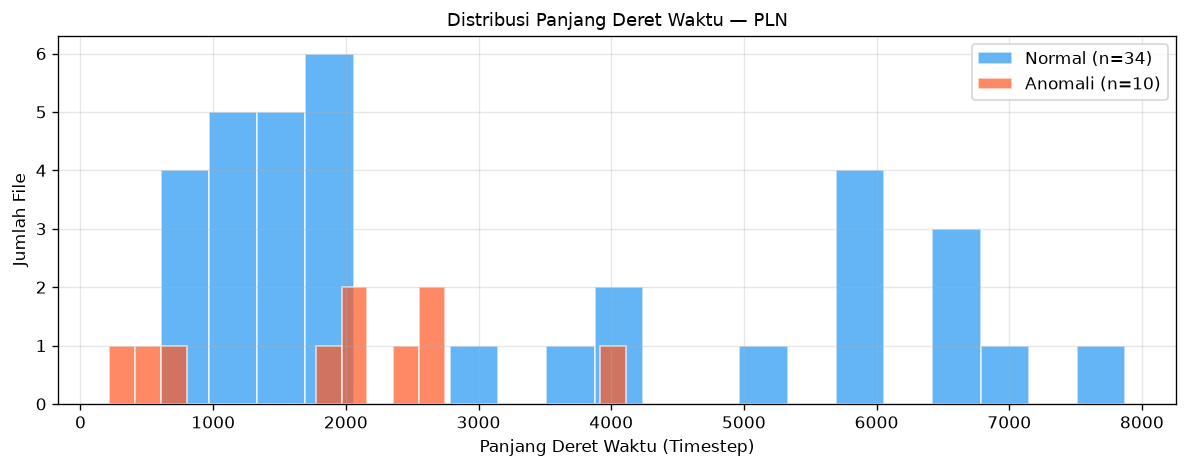

In [7]:
data_dir = DATA_DIR / 'data'
lengths_normal, lengths_anomaly = [], []

for _, row in file_labels.iterrows():
    try:
        arr = np.load(data_dir / row['fname'])
        T = arr.shape[0]
        if row['label'] == 0:
            lengths_normal.append(T)
        else:
            lengths_anomaly.append(T)
    except Exception:
        pass

all_lengths = lengths_normal + lengths_anomaly
print(f"Total file berhasil dimuat : {len(all_lengths)}")
print(f"\nPanjang deret waktu (timestep):")
print(pd.DataFrame({
    'Normal'  : pd.Series(lengths_normal).describe(),
    'Anomali' : pd.Series(lengths_anomaly).describe(),
}).round(1).to_string())

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(lengths_normal,  bins=20, alpha=0.7, color=COLORS['normal'],
        label=f'Normal (n={len(lengths_normal)})', edgecolor='white')
ax.hist(lengths_anomaly, bins=20, alpha=0.7, color=COLORS['anomaly'],
        label=f'Anomali (n={len(lengths_anomaly)})', edgecolor='white')
ax.set_xlabel('Panjang Deret Waktu (Timestep)')
ax.set_ylabel('Jumlah File')
ax.set_title('Distribusi Panjang Deret Waktu — PLN')
ax.legend()
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_pln_lengths.png', bbox_inches='tight')
plt.show()


## 4. Visualisasi Contoh File Normal vs Anomali

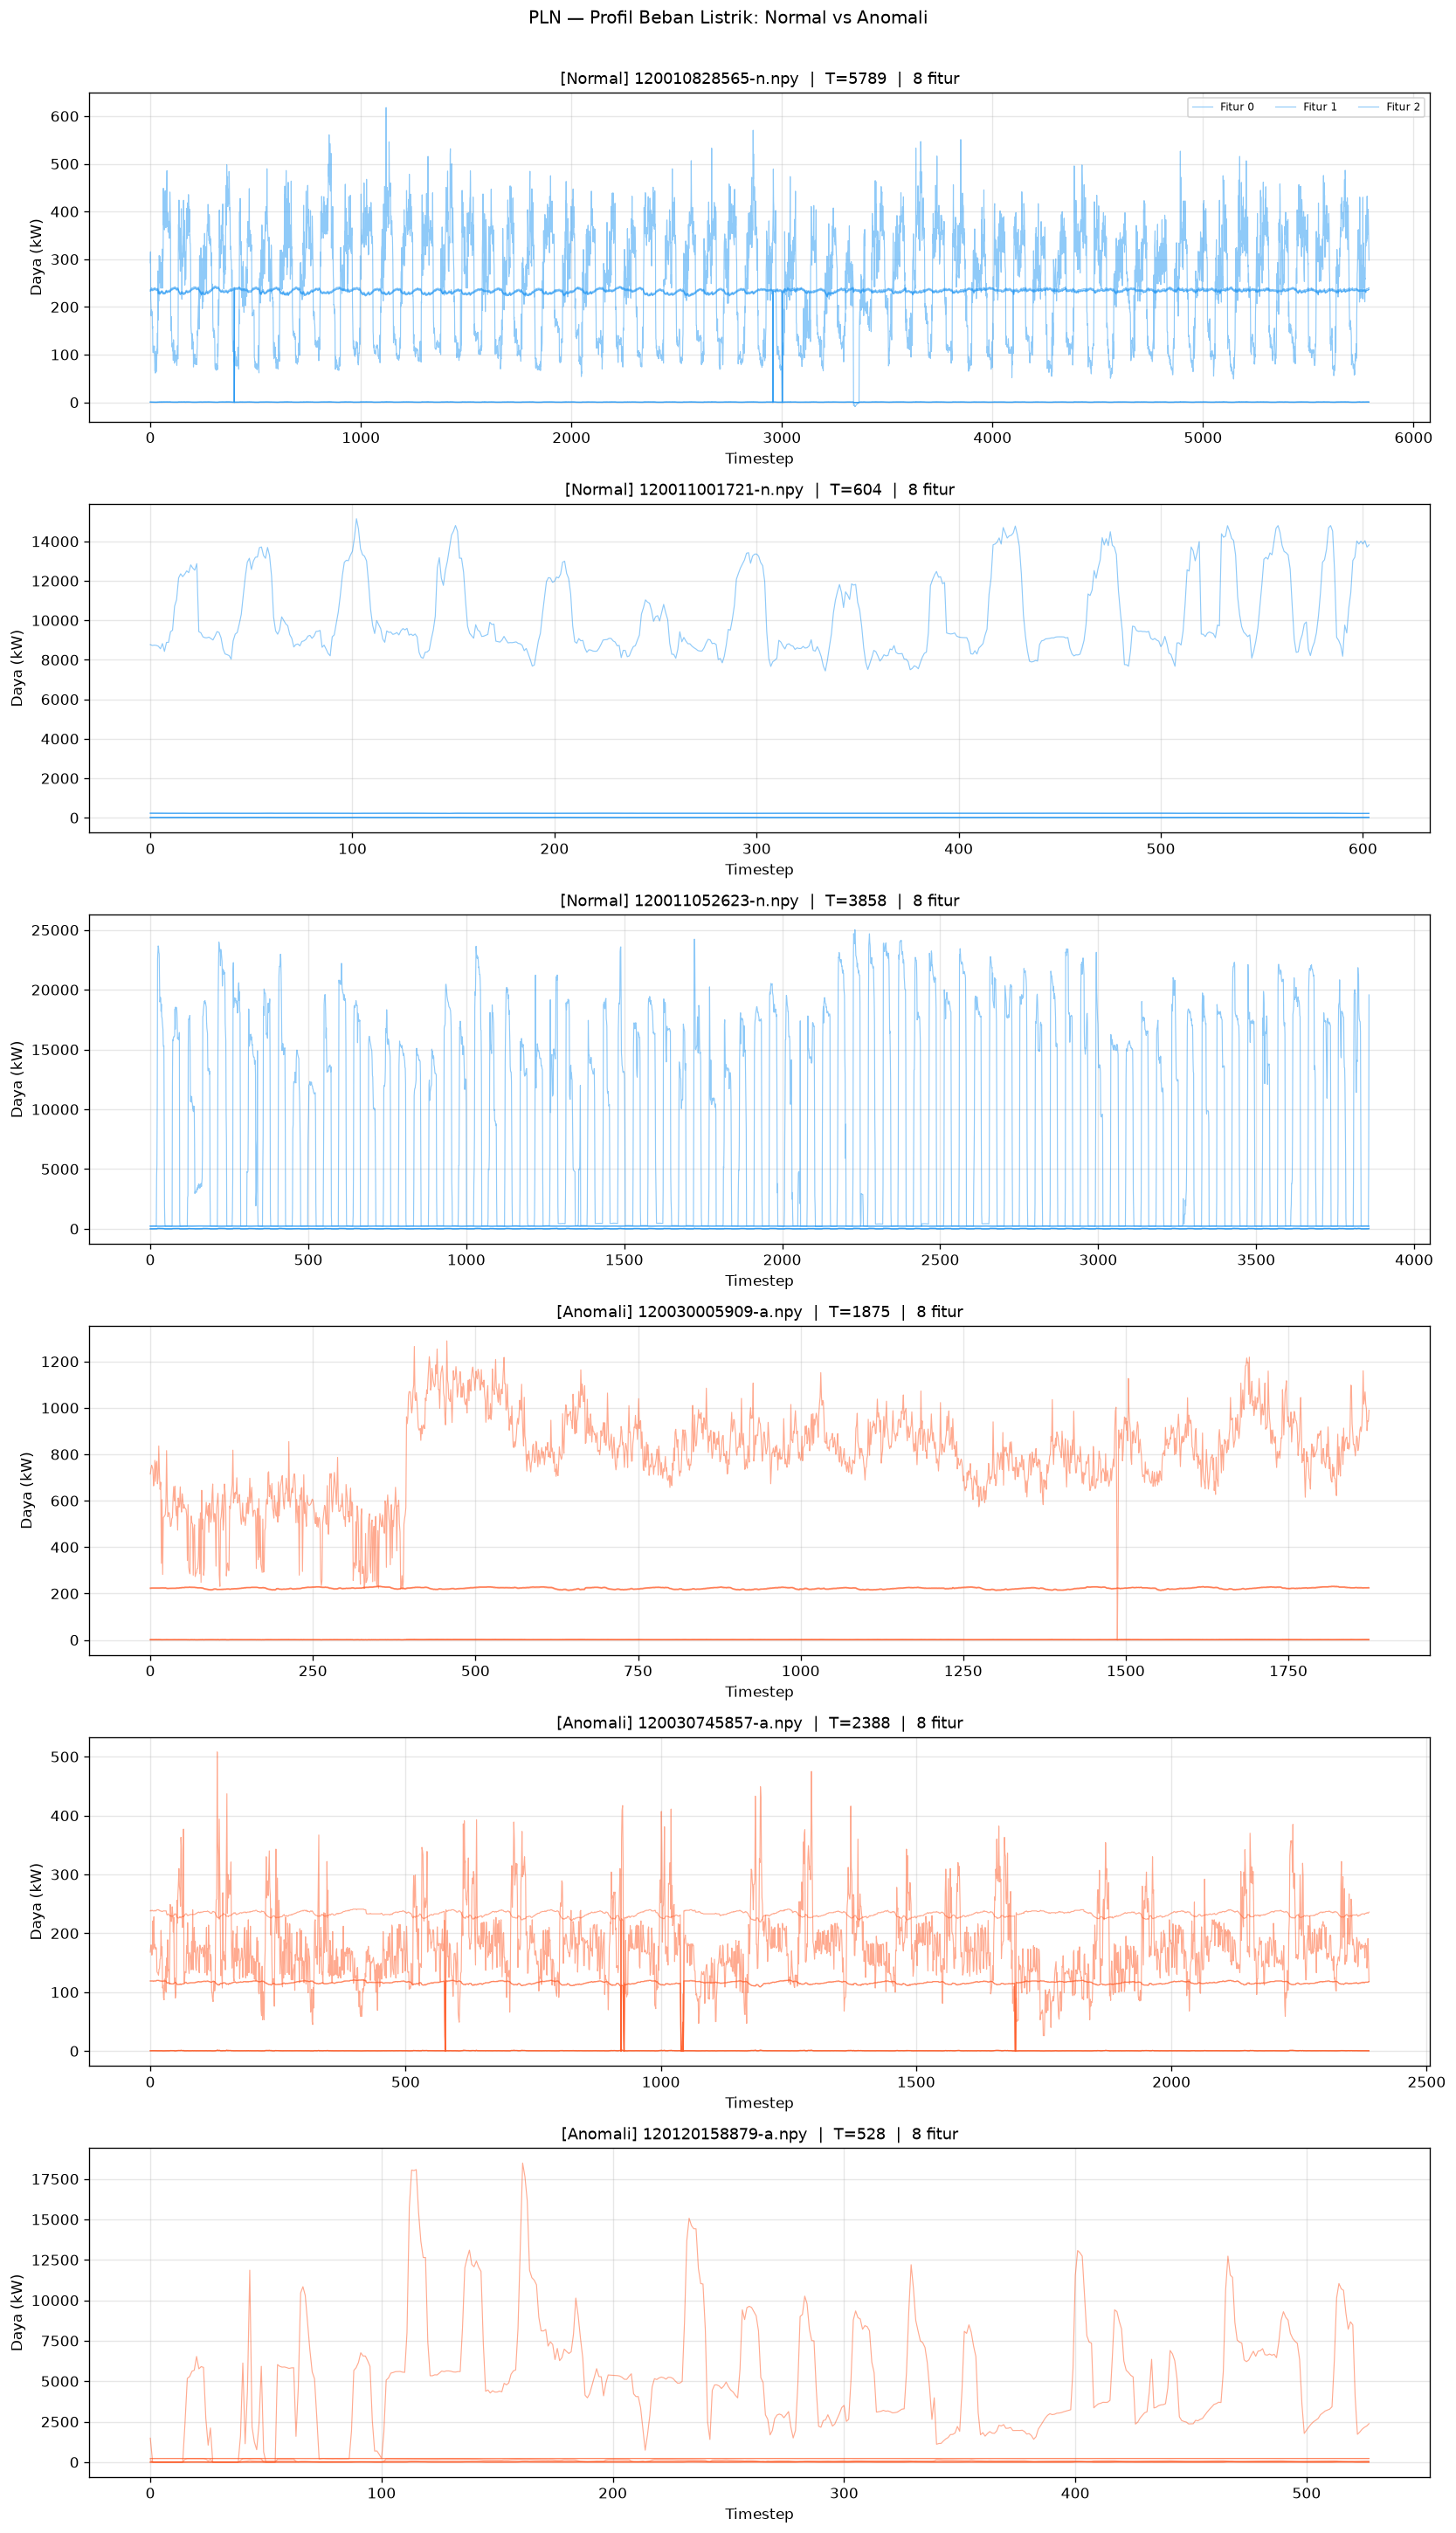

In [8]:
normal_files  = file_labels[file_labels['label'] == 0]['fname'].tolist()
anomaly_files = file_labels[file_labels['label'] == 1]['fname'].tolist()

n_show = min(3, len(normal_files), len(anomaly_files))
fig, axes = plt.subplots(n_show * 2, 1, figsize=(14, 4 * n_show * 2))

row_idx = 0
for category, files, color, label in [
    ('Normal', normal_files[:n_show], COLORS['normal'], 'Normal'),
    ('Anomali', anomaly_files[:n_show], COLORS['anomaly'], 'Anomali'),
]:
    for fname in files[:n_show]:
        try:
            arr = np.load(data_dir / fname)
        except: continue
        ax = axes[row_idx]
        T  = arr.shape[0]
        # Plot semua 8 fitur dengan transparansi
        for ch in range(min(8, arr.shape[1])):
            ax.plot(np.arange(T), arr[:, ch],
                    linewidth=0.7, alpha=0.5,
                    color=color, label=f'Fitur {ch}' if ch < 3 else '_')
        ax.set_title(f'[{label}] {fname}  |  T={T}  |  {arr.shape[1]} fitur')
        ax.set_xlabel('Timestep')
        ax.set_ylabel('Daya (kW)')
        if row_idx == 0:
            ax.legend(fontsize=7, loc='upper right', ncol=4)
        row_idx += 1

plt.suptitle('PLN — Profil Beban Listrik: Normal vs Anomali', fontsize=12, y=1.005)
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_pln_timeseries.png', bbox_inches='tight')
plt.show()


## 5. Statistik Deskriptif Fitur

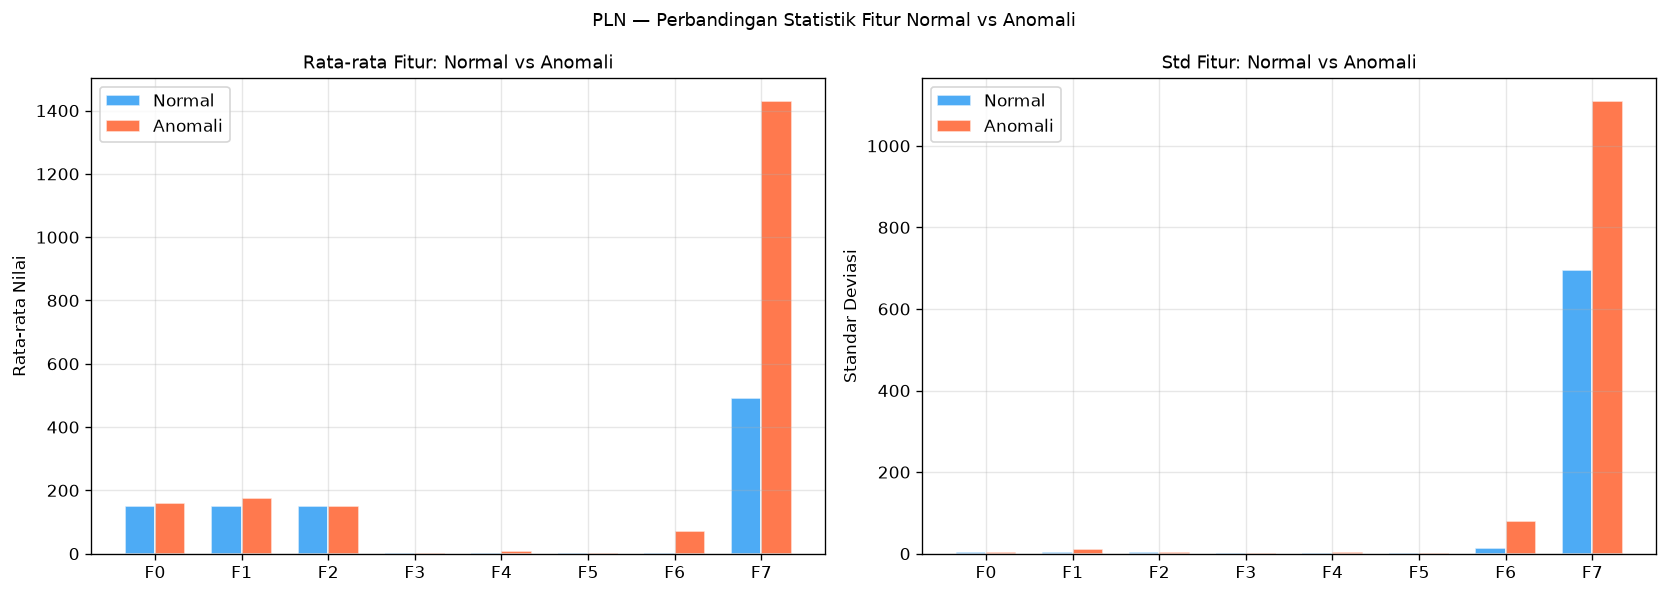

In [9]:
# Agregat statistik dari semua file
means_normal,  stds_normal  = [], []
means_anomaly, stds_anomaly = [], []

for _, row in file_labels.iterrows():
    try:
        arr = np.load(data_dir / row['fname'])
        if row['label'] == 0:
            means_normal.append(np.mean(arr, axis=0))
            stds_normal.append(np.std(arr, axis=0))
        else:
            means_anomaly.append(np.mean(arr, axis=0))
            stds_anomaly.append(np.std(arr, axis=0))
    except: pass

means_normal  = np.array(means_normal)
means_anomaly = np.array(means_anomaly)
stds_normal   = np.array(stds_normal)
stds_anomaly  = np.array(stds_anomaly)

n_feat = means_normal.shape[1]
feat_labels = [f'F{i}' for i in range(n_feat)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(n_feat)
w = 0.35

axes[0].bar(x - w/2, means_normal.mean(axis=0),  w, label='Normal',
            color=COLORS['normal'],  alpha=0.8, edgecolor='white')
axes[0].bar(x + w/2, means_anomaly.mean(axis=0), w, label='Anomali',
            color=COLORS['anomaly'], alpha=0.8, edgecolor='white')
axes[0].set_xticks(x); axes[0].set_xticklabels(feat_labels)
axes[0].set_ylabel('Rata-rata Nilai')
axes[0].set_title('Rata-rata Fitur: Normal vs Anomali')
axes[0].legend()

axes[1].bar(x - w/2, stds_normal.mean(axis=0),  w, label='Normal',
            color=COLORS['normal'],  alpha=0.8, edgecolor='white')
axes[1].bar(x + w/2, stds_anomaly.mean(axis=0), w, label='Anomali',
            color=COLORS['anomaly'], alpha=0.8, edgecolor='white')
axes[1].set_xticks(x); axes[1].set_xticklabels(feat_labels)
axes[1].set_ylabel('Standar Deviasi')
axes[1].set_title('Std Fitur: Normal vs Anomali')
axes[1].legend()

plt.suptitle('PLN — Perbandingan Statistik Fitur Normal vs Anomali', fontsize=11)
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_pln_feature_stats.png', bbox_inches='tight')
plt.show()


## 6. Heatmap Korelasi Fitur (Satu File Representatif)

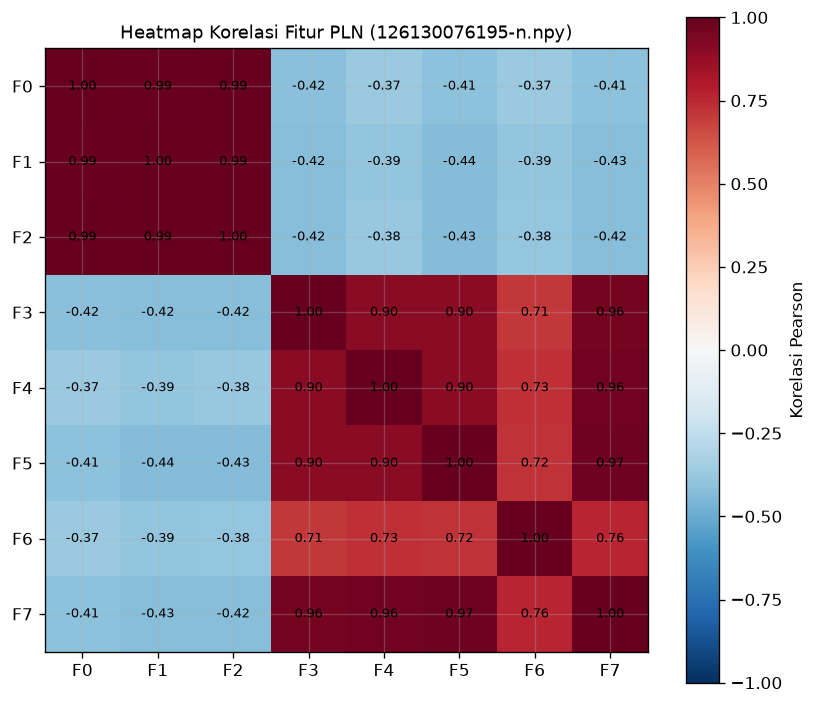

In [10]:
# Pilih file normal terpanjang sebagai representasi
best_fname = max(normal_files, key=lambda f: np.load(data_dir / f).shape[0])
arr  = np.load(data_dir / best_fname)
corr = np.corrcoef(arr.T)   # (8, 8)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
plt.colorbar(im, ax=ax, label='Korelasi Pearson')
ax.set_xticks(range(n_feat)); ax.set_xticklabels(feat_labels)
ax.set_yticks(range(n_feat)); ax.set_yticklabels(feat_labels)
for i in range(n_feat):
    for j in range(n_feat):
        ax.text(j, i, f'{corr[i,j]:.2f}', ha='center', va='center',
                fontsize=8, color='black')
ax.set_title(f'Heatmap Korelasi Fitur PLN ({best_fname})')
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_pln_correlation.png', bbox_inches='tight')
plt.show()


## 7. Analisis Train / Val / Test Split

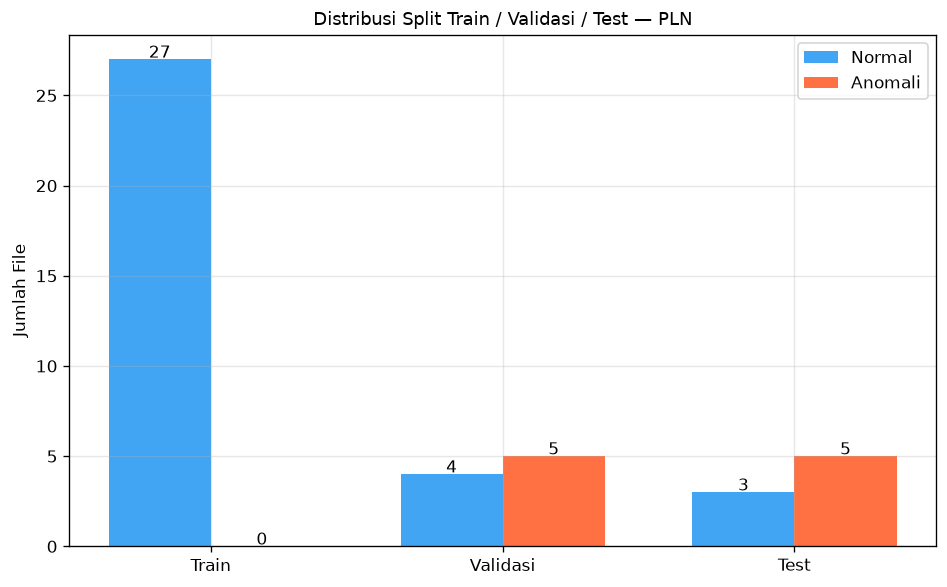

Split        Normal  Anomali    Total
--------------------------------------
Train            27        0       27
Validasi          4        5        9
Test              3        5        8


In [11]:
def read_list(fname):
    p = DATA_DIR / fname
    return [l.strip() for l in p.read_text().splitlines() if l.strip()] if p.exists() else []

train_files = read_list('train_list.txt')
val_files   = read_list('val_list.txt')
test_files  = read_list('test_list.txt')

label_map = dict(zip(file_labels['fname'], file_labels['label']))

def count_labels(files):
    n = sum(1 for f in files if label_map.get(f, 0) == 0)
    a = sum(1 for f in files if label_map.get(f, 0) == 1)
    return n, a

tn, ta = count_labels(train_files)
vn, va = count_labels(val_files)
sn, sa = count_labels(test_files)

splits = ['Train', 'Validasi', 'Test']
normals = [tn, vn, sn]
anomalies = [ta, va, sa]

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(3)
w = 0.35
ax.bar(x - w/2, normals,   w, label='Normal',  color=COLORS['normal'],  alpha=0.85)
ax.bar(x + w/2, anomalies, w, label='Anomali', color=COLORS['anomaly'], alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(splits)
ax.set_ylabel('Jumlah File')
ax.set_title('Distribusi Split Train / Validasi / Test — PLN')
ax.legend()
for i, (n, a) in enumerate(zip(normals, anomalies)):
    ax.text(i - w/2, n + 0.1, str(n), ha='center', fontsize=10)
    ax.text(i + w/2, a + 0.1, str(a), ha='center', fontsize=10)
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_pln_split.png', bbox_inches='tight')
plt.show()

print(f"{'Split':10s} {'Normal':>8s} {'Anomali':>8s} {'Total':>8s}")
print("-" * 38)
for s, n, a in zip(splits, normals, anomalies):
    print(f"{s:10s} {n:>8d} {a:>8d} {n+a:>8d}")


## 8. Ringkasan Dataset PLN

In [12]:
print("=" * 55)
print("RINGKASAN DATASET PLN")
print("=" * 55)
total = len(file_labels)
n_normal  = (file_labels['label'] == 0).sum()
n_anomaly = (file_labels['label'] == 1).sum()
print(f"Total file pelanggan         : {total}")
print(f"Normal (label 0)             : {n_normal}  ({n_normal/total*100:.1f}%)")
print(f"Anomali (label 1)            : {n_anomaly}  ({n_anomaly/total*100:.1f}%)")
print(f"Jumlah fitur per timestep    : {arr.shape[1]}")
print(f"Rata-rata panjang TS normal  : {np.mean(lengths_normal):.0f} timestep")
print(f"Rata-rata panjang TS anomali : {np.mean(lengths_anomaly):.0f} timestep")
print(f"Label anomali                : per FILE (bukan per timestep)")
print(f"Evaluasi CARLA               : agregasi window → file-level score")
print(f"\nSplit:")
print(f"  Train   : {len(train_files)} file ({tn} normal, {ta} anomali)")
print(f"  Val     : {len(val_files)} file ({vn} normal, {va} anomali)")
print(f"  Test    : {len(test_files)} file ({sn} normal, {sa} anomali)")


RINGKASAN DATASET PLN
Total file pelanggan         : 44
Normal (label 0)             : 34  (77.3%)
Anomali (label 1)            : 10  (22.7%)
Jumlah fitur per timestep    : 8
Rata-rata panjang TS normal  : 3108 timestep
Rata-rata panjang TS anomali : 1918 timestep
Label anomali                : per FILE (bukan per timestep)
Evaluasi CARLA               : agregasi window → file-level score

Split:
  Train   : 27 file (27 normal, 0 anomali)
  Val     : 9 file (4 normal, 5 anomali)
  Test    : 8 file (3 normal, 5 anomali)
